# P3 Movie Genre, Notebook 1: Exploratory Data Analysis
**Team:** DataStars &nbsp;|&nbsp; **Course:** MSDS 565, Unit 3 Text Classification

Goal: understand the movies, the genre labels and the plot text in `mpst_imdb_movies.csv` before anything is modeled. The only model input in this project is `plot_synopsis`. `startYear`, `runtimeMinutes`, `averageRating` and `numVotes` are used here for analysis and for the vote filter only, never as features.

This notebook does EDA and nothing else: no train/test modeling, no vectorizing. It ends with one decision that Notebooks 2 and 3 reuse, the minimum-votes filter (section 2.3).

## 0. Setup and loading

In [1]:
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

pd.set_option('display.width', 150)
pd.set_option('display.max_columns', 30)
sns.set_style('whitegrid')

# The CSV is provided by the course and is kept outside the repo.
DATA_PATH = Path.home() / 'MSDS565_data' / 'mpst_imdb_movies.csv'

df = pd.read_csv(DATA_PATH)
META = ['imdb_id', 'primaryTitle', 'plot_synopsis', 'synopsis_source', 'split',
        'startYear', 'runtimeMinutes', 'averageRating', 'numVotes']
GENRES = [c for c in df.columns if c not in META]    # one 0/1 column per genre
SPLITS = ['train', 'val', 'test']
print(f'Rows: {len(df):,}  |  Columns: {df.shape[1]}  |  Genre columns: {len(GENRES)}')
df[META].drop(columns='plot_synopsis').head(3)

Rows: 11,824  |  Columns: 33  |  Genre columns: 24


,imdb_id,primaryTitle,synopsis_source,split,startYear,runtimeMinutes,averageRating,numVotes
0,tt0057603,Black Sabbath,imdb,train,1963.0,92.0,7.0,12895
1,tt0033045,The Shop Around the Corner,imdb,test,1940.0,99.0,8.0,35221
2,tt0113862,Mr. Holland's Opus,imdb,train,1995.0,143.0,7.3,40547


## 1. Structure

### 1.1 Missing values, duplicates and the provided splits

In [2]:
missing = df.isna().sum()
print('Missing values (columns with any):')
print(missing[missing > 0].to_string())
print(f"\nDuplicate imdb_id: {df['imdb_id'].duplicated().sum()}")
print(f"Empty synopses:    {(df['plot_synopsis'].str.strip().str.len() == 0).sum()}")
pd.crosstab(df['split'], df['synopsis_source']).reindex(SPLITS).assign(total=lambda t: t.sum(axis=1))

Missing values (columns with any):
startYear         1
runtimeMinutes    7

Duplicate imdb_id: 0
Empty synopses:    0


synopsis_source,imdb,wikipedia,total
split,,,
train,2401,5195,7596
val,609,1259,1868
test,781,1579,2360


**Interpretation:** The file has 11,824 movies and 33 columns: 9 metadata columns and 24 genre columns. There are no duplicate IDs and no empty synopses. Only `startYear` (1 movie) and `runtimeMinutes` (7 movies) have gaps, and neither column is a model input, so nothing needs repair. The provided split is 64% train (7,596), 16% validation (1,868) and 20% test (2,360). About two thirds of the synopses in every split come from Wikipedia (67% to 68%), so the splits are comparable by source. Notebook 2 will train on train + val and score on test.

## 2. Movie characteristics

### 2.1 Distributions of year, runtime, rating and votes

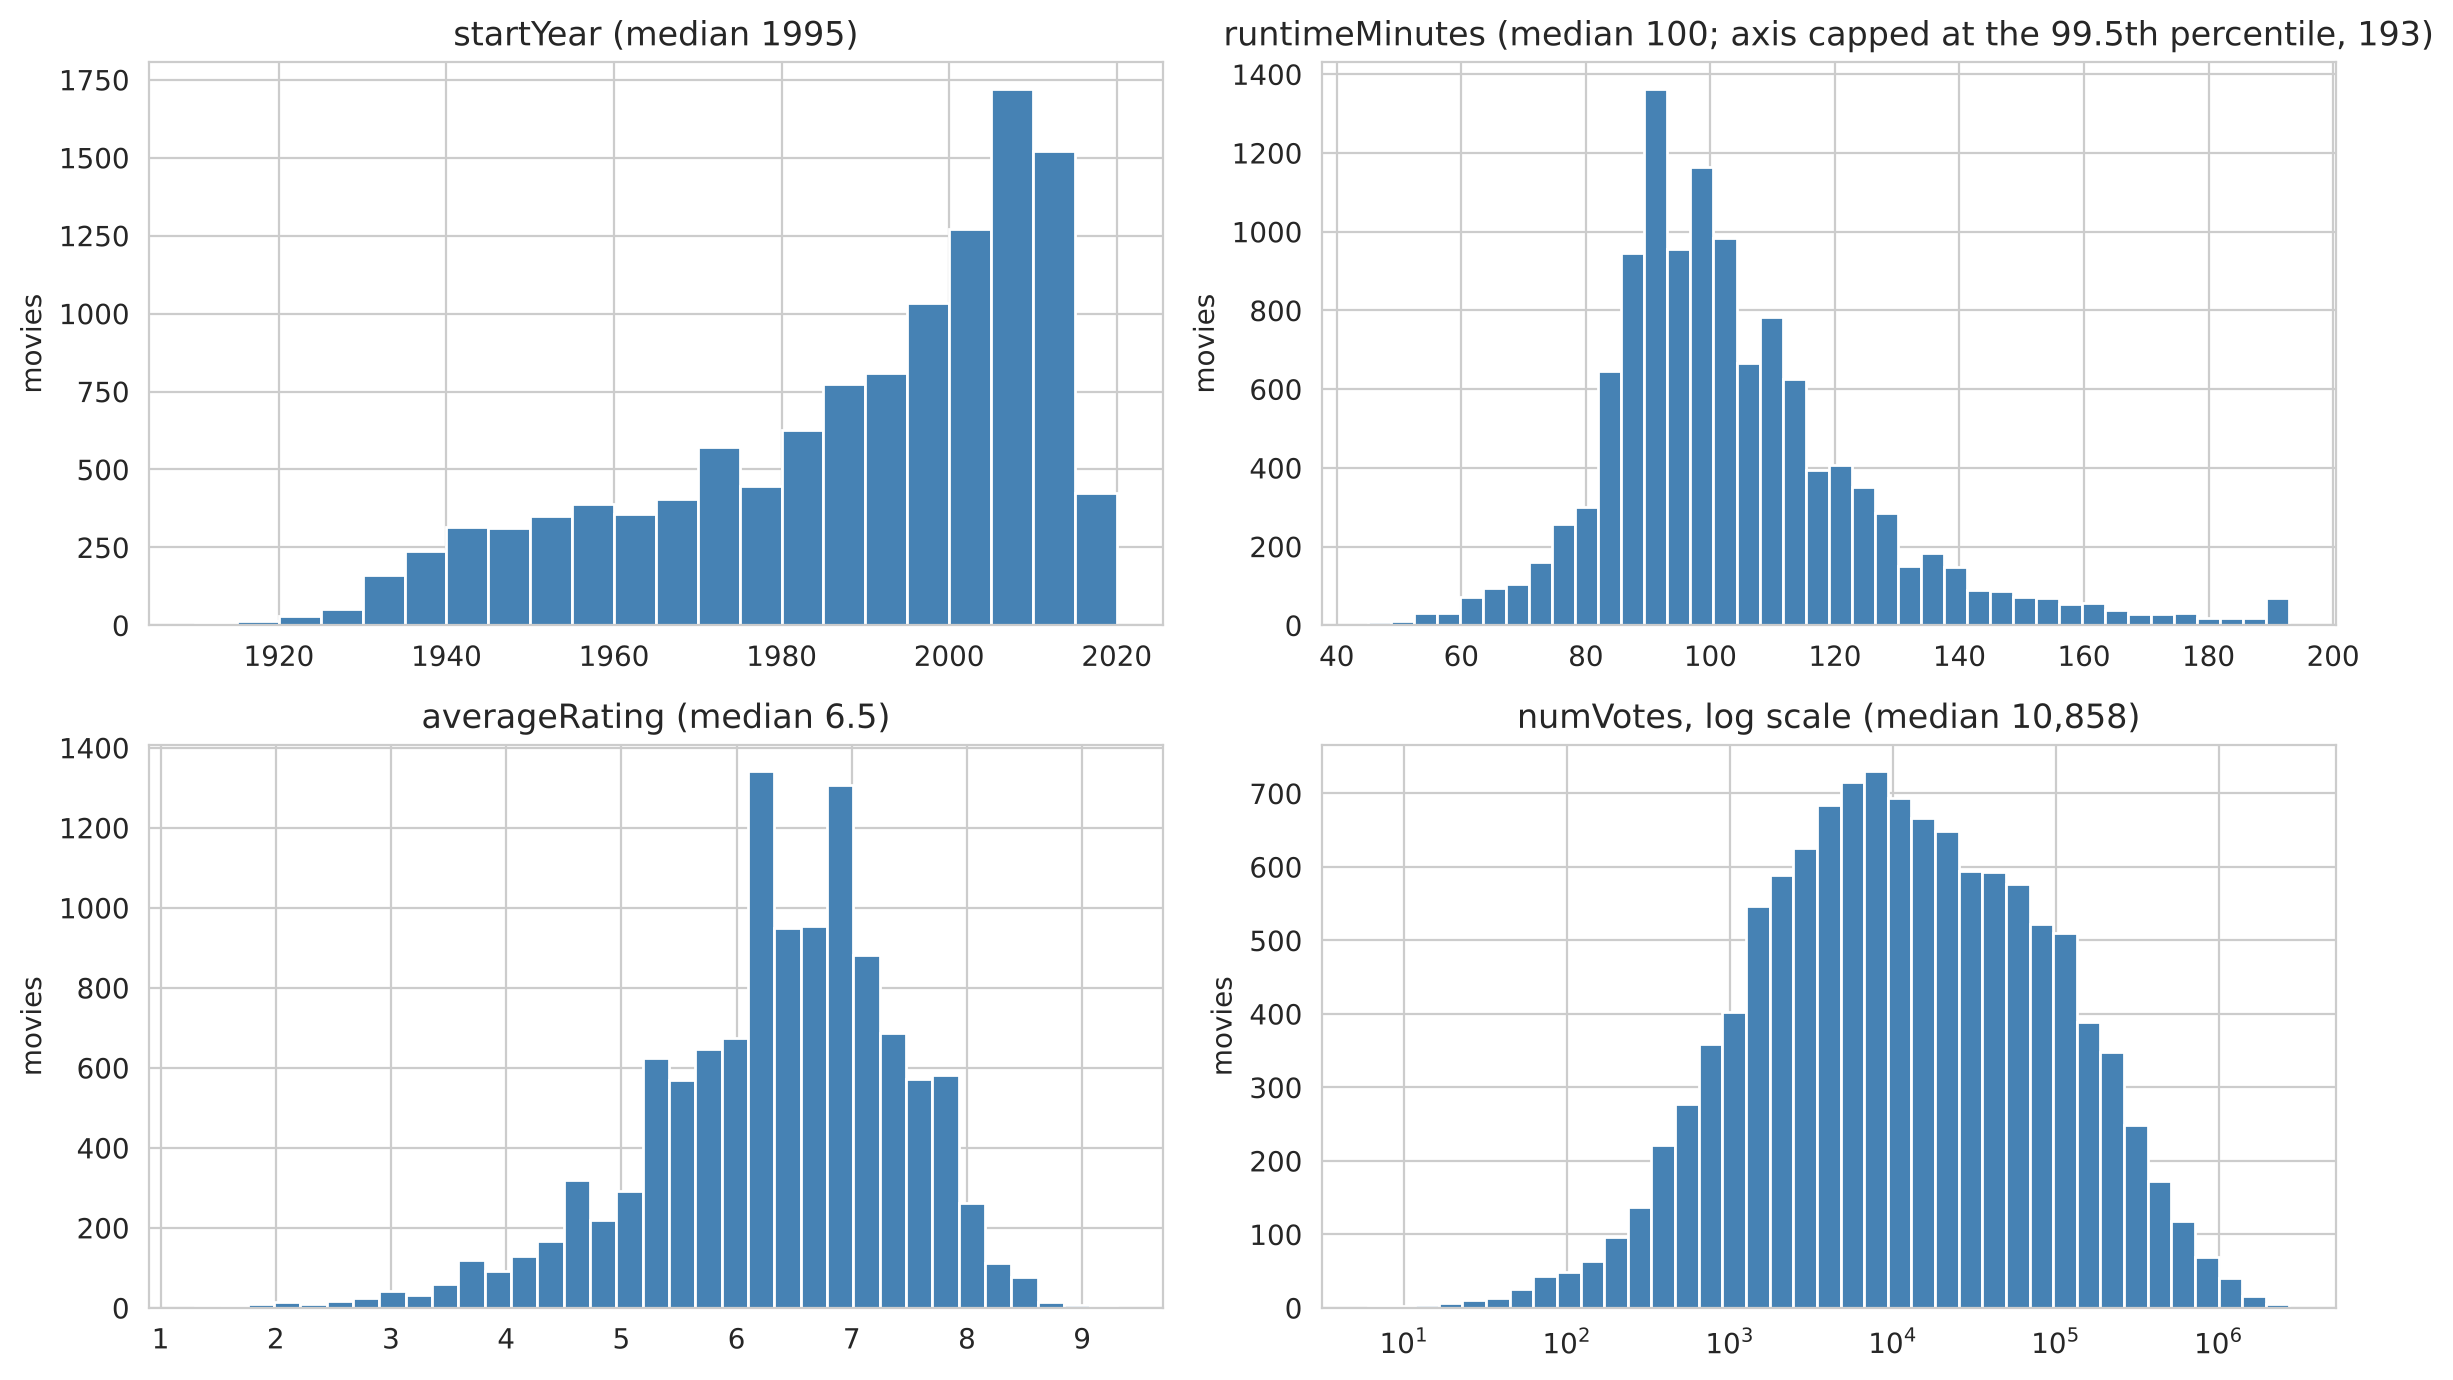

,startYear,runtimeMinutes,averageRating,numVotes
min,1911.0,45.0,1.3,6.0
25%,1972.0,90.0,5.7,2600.0
50%,1995.0,100.0,6.5,10858.0
75%,2007.0,113.0,7.1,51224.8
max,2020.0,566.0,9.3,2724626.0


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

ax = axes[0, 0]
ax.hist(df['startYear'].dropna(), bins=range(1910, 2025, 5), color='steelblue', edgecolor='white')
ax.set_title(f"startYear (median {df['startYear'].median():.0f})")

ax = axes[0, 1]
cap = df['runtimeMinutes'].quantile(0.995)
ax.hist(df['runtimeMinutes'].dropna().clip(upper=cap), bins=40, color='steelblue', edgecolor='white')
ax.set_title(f"runtimeMinutes (median {df['runtimeMinutes'].median():.0f}; axis capped at the 99.5th percentile, {cap:.0f})")

ax = axes[1, 0]
ax.hist(df['averageRating'], bins=35, color='steelblue', edgecolor='white')
ax.set_title(f"averageRating (median {df['averageRating'].median():.1f})")

ax = axes[1, 1]
ax.hist(df['numVotes'], bins=np.logspace(np.log10(df['numVotes'].min()), np.log10(df['numVotes'].max()), 40),
        color='steelblue', edgecolor='white')
ax.set_xscale('log')
ax.set_title(f"numVotes, log scale (median {df['numVotes'].median():,.0f})")

for ax in axes.ravel():
    ax.set_ylabel('movies')
plt.tight_layout()
plt.show()
df[['startYear', 'runtimeMinutes', 'averageRating', 'numVotes']].describe().loc[['min', '25%', '50%', '75%', 'max']].round(1)

**Interpretation:** The movies span 1911 to 2020 and lean recent: a quarter were released before 1972 and a quarter after 2007 (median 1995). Runtime is centered at 100 minutes (middle half 90 to 113) with a long right tail to 566 minutes; 114 movies run past three hours, which is why the display axis is capped. Ratings are left-skewed with a median of 6.5 and a middle half of 5.7 to 7.1, from a low of 1.3 to a high of 9.3. Votes span more than five orders of magnitude (6 to 2.7 million, median 10,858), so only the log scale shows the shape. On a linear axis nearly every movie would sit in the first bar.

### 2.2 Average rating by genre

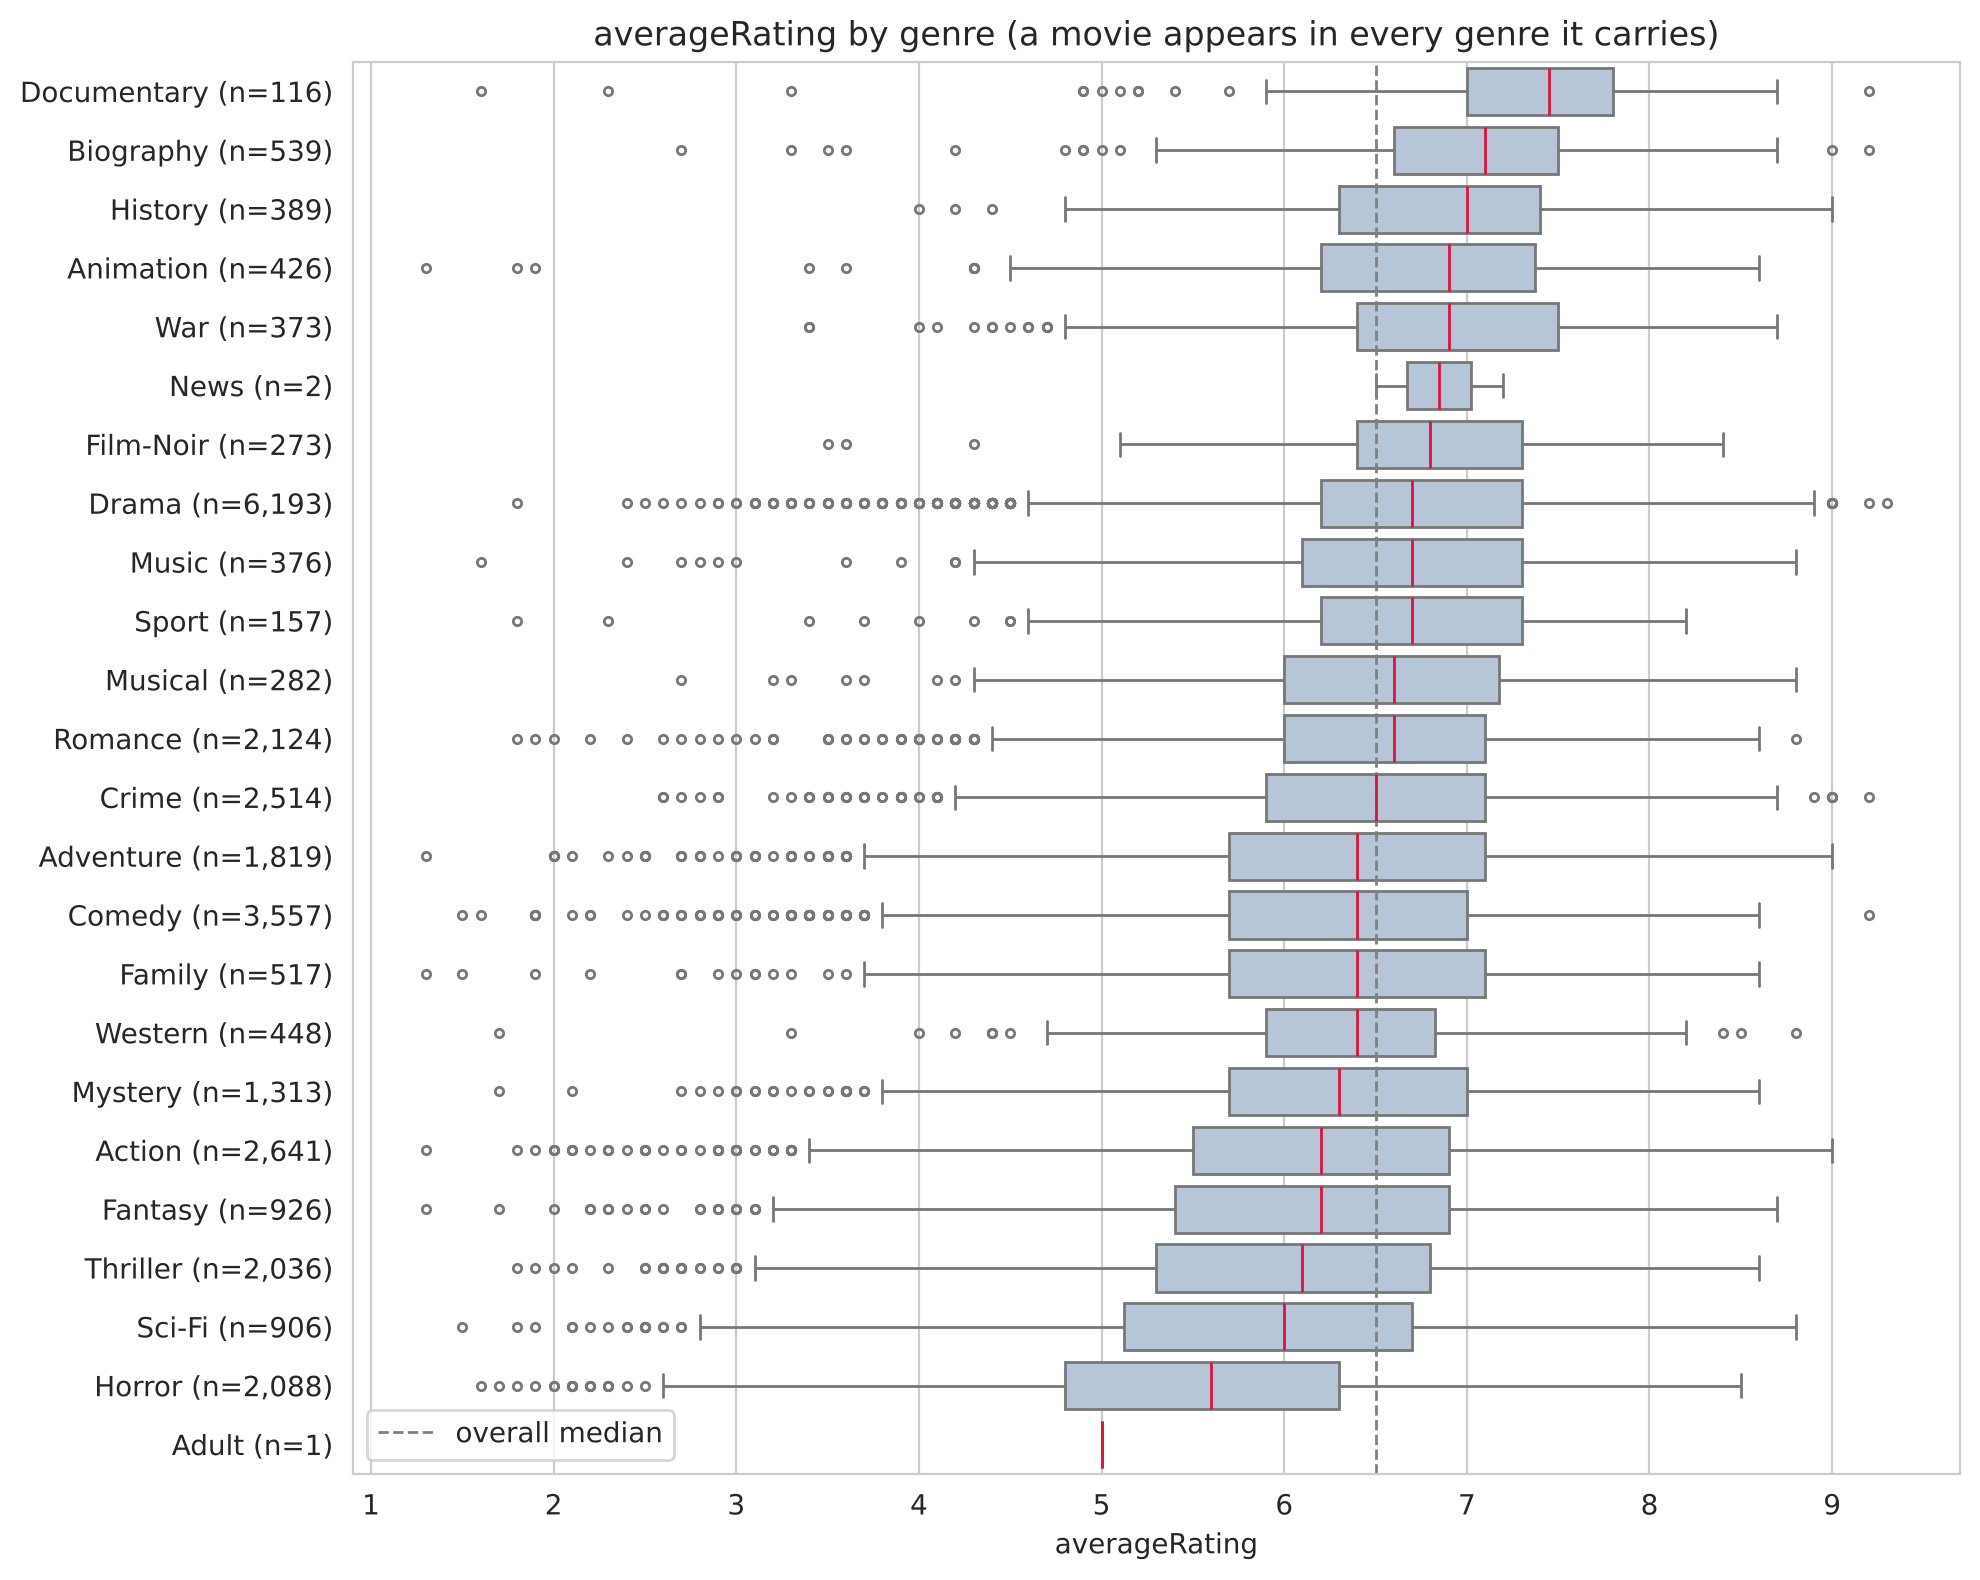

In [4]:
order = sorted(GENRES, key=lambda g: -df.loc[df[g] == 1, 'averageRating'].median())    # highest median on top
label = {g: f"{g} (n={int(df[g].sum()):,})" for g in GENRES}
long = pd.concat([pd.DataFrame({'genre': label[g], 'averageRating': df.loc[df[g] == 1, 'averageRating']}) for g in GENRES])
fig, ax = plt.subplots(figsize=(10, 8))
sns.boxplot(data=long, x='averageRating', y='genre', order=[label[g] for g in order], orient='h', color='lightsteelblue',
            fliersize=3, medianprops={'color': 'crimson'}, ax=ax)
ax.axvline(df['averageRating'].median(), color='grey', linestyle='--', linewidth=1, label='overall median')
ax.set_ylabel('')
ax.set_title('averageRating by genre (a movie appears in every genre it carries)')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

**Interpretation:** Genre carries some information about rating, but the boxes overlap heavily. Documentary (median 7.45), Biography (7.1) and History (7.0) rate highest. Horror (5.6), Sci-Fi (6.0) and Thriller (6.1) rate lowest, against an overall median of 6.5. Even the extremes differ by under two points, and most boxes are roughly a point wide, so rating cannot stand in for genre. Adult (n=1) and News (n=2) are too small to read. Rating is not a model input in this project.

### 2.3 Vote filter

Ratings and genre labels of barely-voted movies are the least trustworthy part of the data, and obscure titles tend to come with thin synopses. The first table shows how votes relate to rating spread, synopsis length and synopsis source. The second shows the cost of a few candidate cut-offs: rows dropped per split and the largest change in any genre's positive rate.

In [5]:
vote_bins = pd.cut(df['numVotes'], [0, 100, 500, 1000, 2500, 5000, 10000, np.inf], right=False,
                   labels=['<100', '100-499', '500-999', '1,000-2,499', '2,500-4,999', '5,000-9,999', '10,000+'])
by_votes = (df.assign(chars=df['plot_synopsis'].str.len(), wikipedia=df['synopsis_source'].eq('wikipedia'))
              .groupby(vote_bins, observed=True)
              .agg(movies=('imdb_id', 'size'), mean_rating=('averageRating', 'mean'), rating_sd=('averageRating', 'std'),
                   median_synopsis_chars=('chars', 'median'), share_wikipedia=('wikipedia', 'mean')))
by_votes.round(2)

,movies,mean_rating,rating_sd,median_synopsis_chars,share_wikipedia
numVotes,,,,,
<100,129,6.08,1.06,2765.0,0.94
100-499,606,5.51,0.99,2338.5,0.88
500-999,704,5.62,1.09,2537.0,0.86
"1,000-2,499",1454,5.83,1.11,2932.0,0.82
"2,500-4,999",1361,6.08,1.07,3125.0,0.82
"5,000-9,999",1483,6.27,1.02,3540.0,0.78
"10,000+",6087,6.69,0.97,4784.0,0.54


In [6]:
def cutoff_cost(t):
    dropped = df.loc[df['numVotes'] < t, 'split'].value_counts().reindex(SPLITS, fill_value=0)
    shift = (df.loc[df['numVotes'] >= t, GENRES].mean() - df[GENRES].mean()) * 100
    return {'min_votes': t, 'dropped': int(dropped.sum()), 'dropped_pct': round(100 * dropped.sum() / len(df), 1),
            **{f'{s}_dropped': int(dropped[s]) for s in SPLITS},
            'max_genre_shift_pts': round(shift.abs().max(), 2), 'most_shifted_genre': shift.abs().idxmax()}

pd.DataFrame([cutoff_cost(t) for t in (100, 250, 500, 1000, 2500)]).set_index('min_votes')

,dropped,dropped_pct,train_dropped,val_dropped,test_dropped,max_genre_shift_pts,most_shifted_genre
min_votes,,,,,,,
100,129,1.1,79,20,30,0.26,Western
250,337,2.9,202,56,79,0.69,Western
500,735,6.2,474,110,151,1.05,Western
1000,1439,12.2,949,205,285,1.52,Comedy
2500,2893,24.5,1909,425,559,2.85,Comedy


**Interpretation:** Movies with few votes have thinner text. Median synopsis length is about 2,300 characters for 100 to 499 votes and about 2,500 for 500 to 999, against about 4,800 for movies above 10,000 votes, and the share of Wikipedia synopses rises from 54% (10,000+) to 94% (under 100). Mean rating also climbs from 5.5 (100 to 499 votes) to 6.7 (10,000+), but the rating spread barely changes (about 1.0 to 1.1), so noisy ratings are a weak reason to filter. Thin text is the stronger reason, because a classifier learns less from a short synopsis. The cut-off table shows the cost: a minimum of 500 drops 735 movies (6.2%) and moves no genre rate by more than 1.05 points, 1,000 drops 12.2% and moves Comedy by 1.52 points, and 2,500 drops 24.5% and moves a rate by 2.85 points.

In [7]:
MIN_VOTES = 500          # applied again in Notebooks 2 and 3

keep = df['numVotes'] >= MIN_VOTES
before = df['split'].value_counts().reindex(SPLITS)
dropped = df.loc[~keep, 'split'].value_counts().reindex(SPLITS)
report = pd.DataFrame({'before': before, 'dropped': dropped, 'dropped_pct': (100 * dropped / before).round(1),
                       'after': before - dropped})
report.loc['all'] = [before.sum(), dropped.sum(), round(100 * dropped.sum() / before.sum(), 1), (before - dropped).sum()]
movies = df[keep].reset_index(drop=True)     # every section below uses the filtered data
report

,before,dropped,dropped_pct,after
split,,,,
train,7596.0,474.0,6.2,7122.0
val,1868.0,110.0,5.9,1758.0
test,2360.0,151.0,6.4,2209.0
all,11824.0,735.0,6.2,11089.0


**Decision:** `MIN_VOTES = 500`. It removes the thinnest tail (735 movies, 6.2%) without turning the dataset into a popularity contest. The drop is proportional across splits (train 6.2%, val 5.9%, test 6.4%), so the split ratios stay at about 64/16/20: 7,122 train, 1,758 val and 2,209 test movies remain, 11,089 in all. Higher cut-offs cost far more rows and shift the genre mix more. The largest shift at 500 is Western, which falls from 3.8% to 2.7% of movies, so low-vote movies are over-represented among Westerns. Notebooks 2 and 3 apply the same rule.

## 3. Genre and class balance

From here on, all analysis uses the vote-filtered `movies` table.

### 3.1 Positive counts and rates for all genres

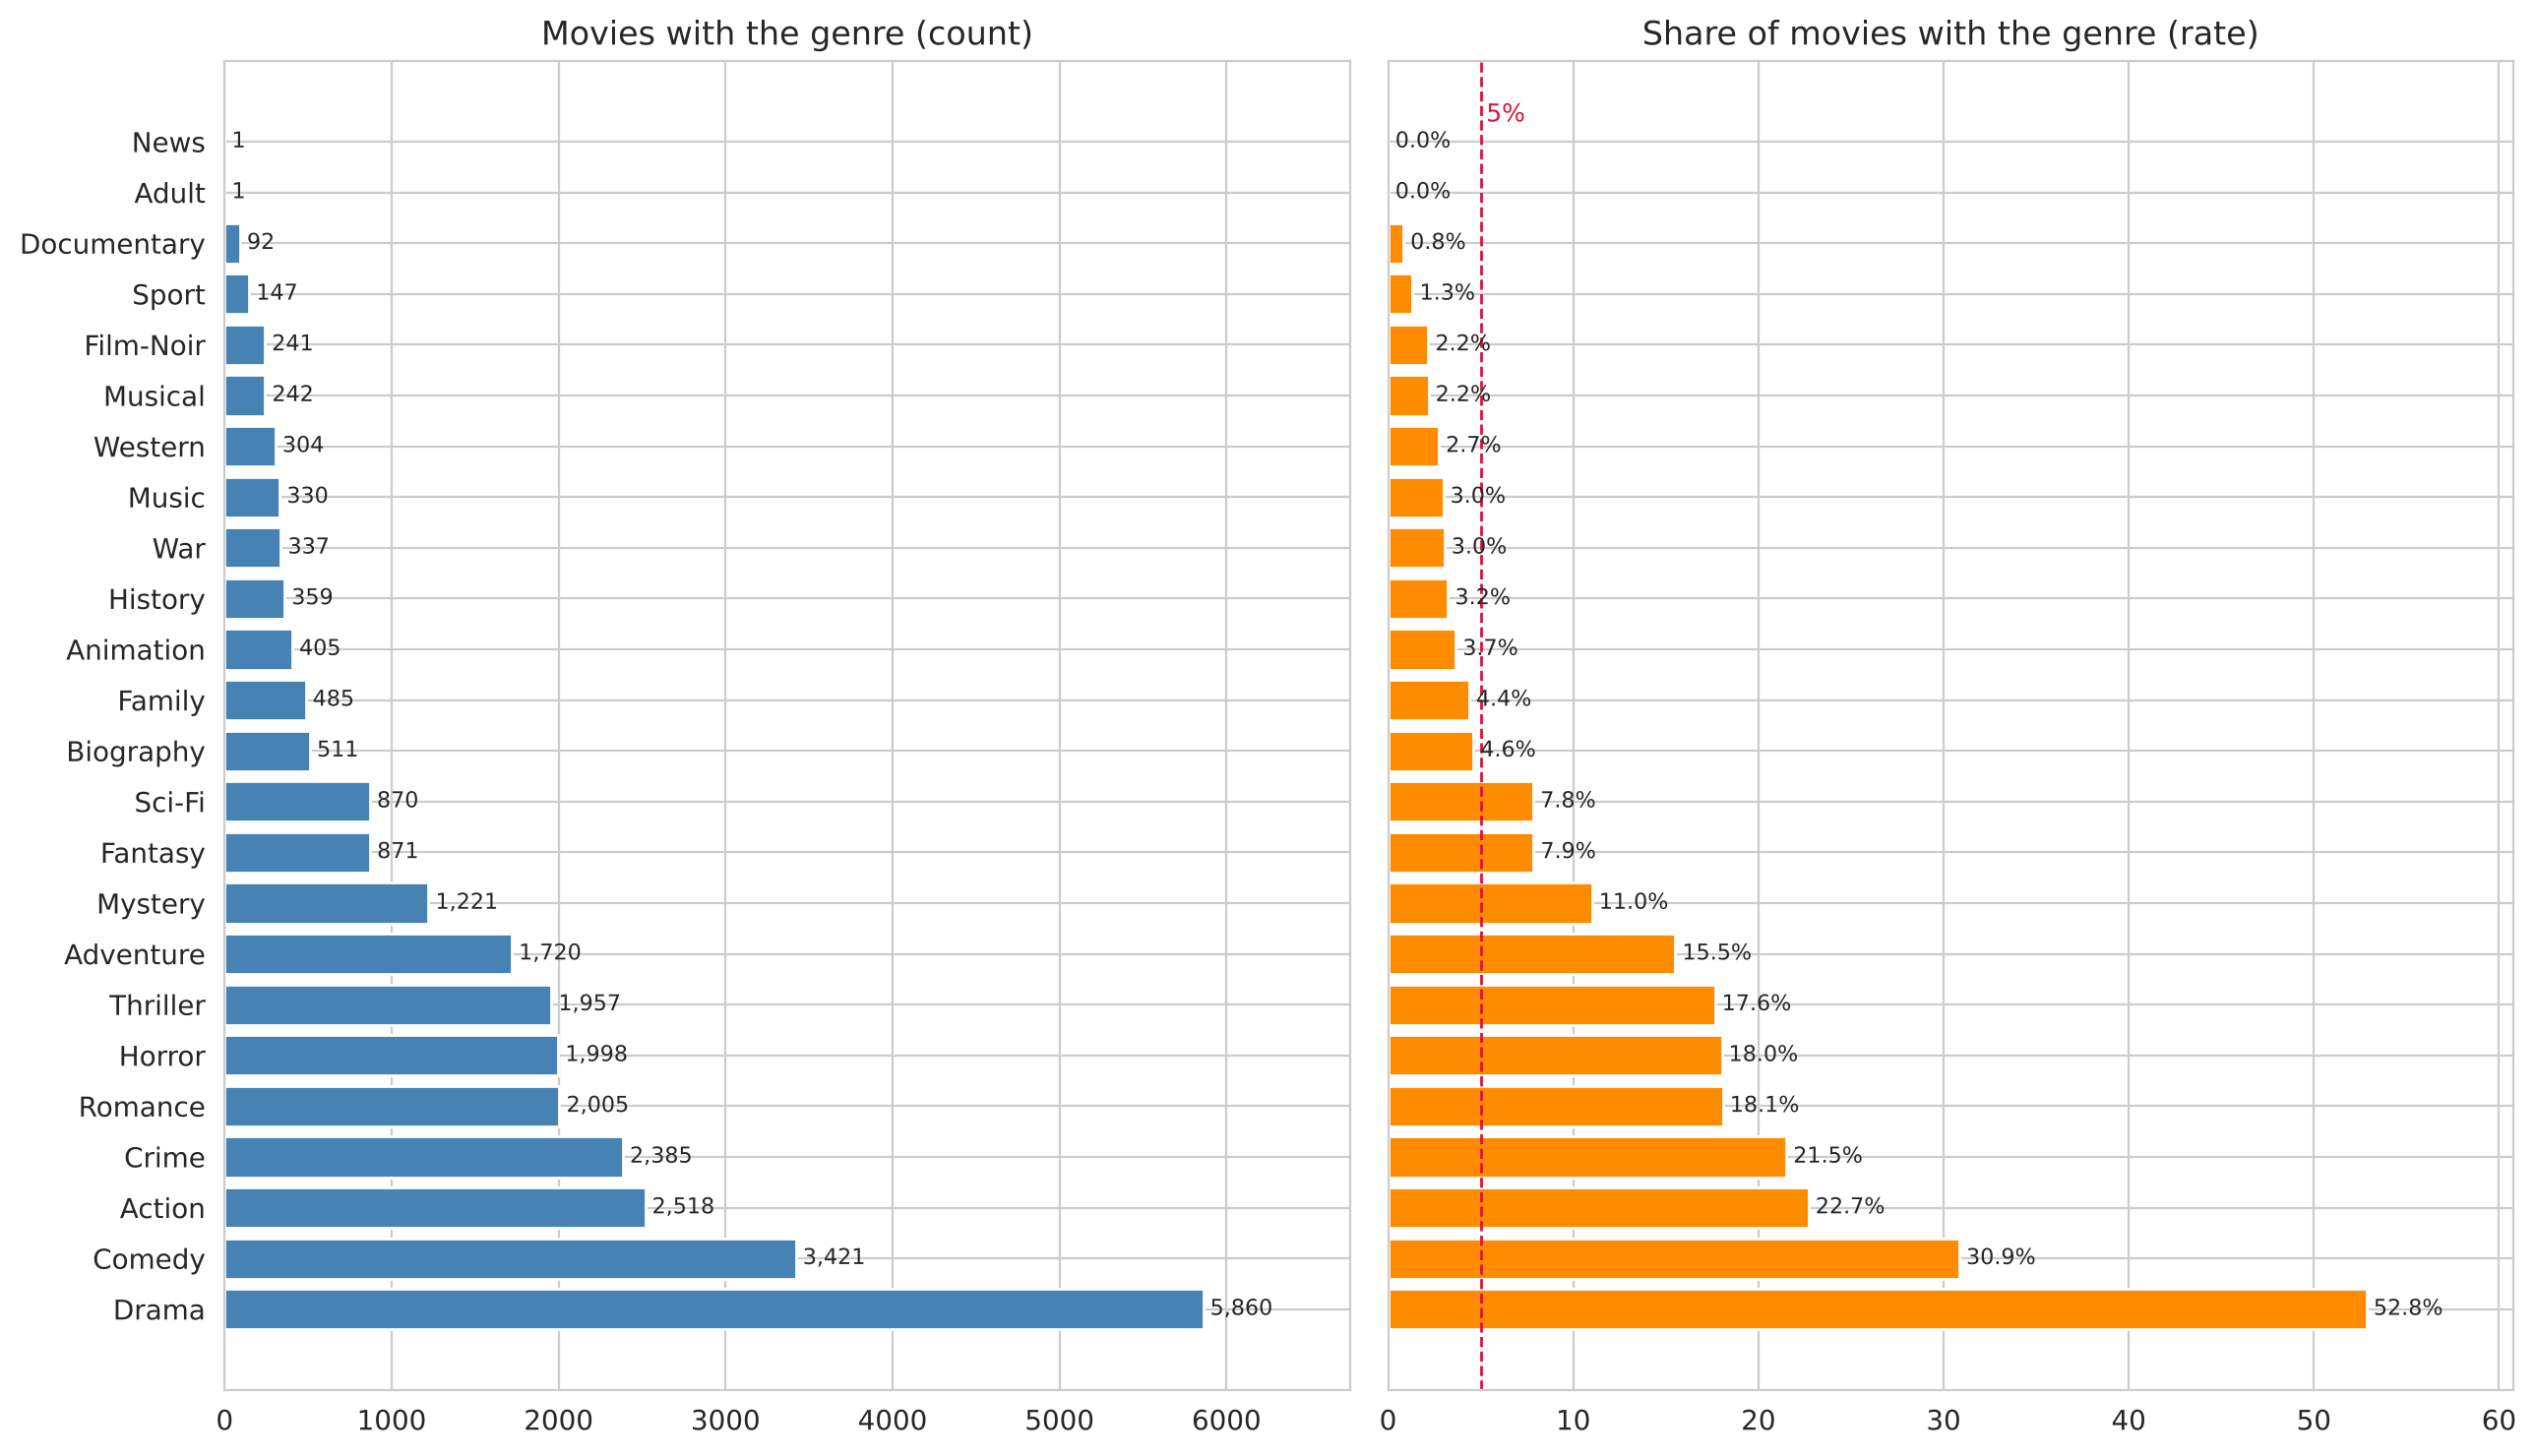

Genres under 5% positives: Biography, Family, Animation, History, War, Music, Western, Musical, Film-Noir, Sport, Documentary, Adult, News


In [8]:
balance = pd.DataFrame({'positives': movies[GENRES].sum(), 'rate_pct': movies[GENRES].mean() * 100})
balance = balance.sort_values('positives', ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 7.5), sharey=True)
ax1.barh(balance.index, balance['positives'], color='steelblue')
ax2.barh(balance.index, balance['rate_pct'], color='darkorange')
for ax, col, fmt in ((ax1, 'positives', '{:,.0f}'), (ax2, 'rate_pct', '{:.1f}%')):
    for y, v in enumerate(balance[col]):
        ax.text(v, y, ' ' + fmt.format(v), va='center', fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, balance[col].max() * 1.15)
ax2.axvline(5, color='crimson', linestyle='--', linewidth=1)
ax2.text(5.3, len(balance) - 0.6, '5%', color='crimson', fontsize=9)
ax1.set_title('Movies with the genre (count)')
ax2.set_title('Share of movies with the genre (rate)')
plt.tight_layout()
plt.show()
print(f"Genres under 5% positives: {', '.join(balance.index[balance['rate_pct'] < 5])}")

**Interpretation:** After the vote filter there are 11,089 movies and the genres are very unbalanced. Drama is on 52.8% of movies, Comedy on 30.9%, Action 22.7%, Crime 21.5%, Romance 18.1%, Horror 18.0% and Thriller 17.6%. Thirteen genres fall under 5%: Biography (4.6%), Family, Animation, History, War, Music, Western, Musical, Film-Noir, Sport, Documentary (0.8%), and Adult and News with a single movie each. Notebook 2 requires at least 5% positives in both train and test, so only 11 genres are eligible: Drama, Comedy, Action, Crime, Romance, Horror, Thriller, Adventure, Mystery, Fantasy and Sci-Fi. Even the rarest of those (Sci-Fi at 7.8%) is about 1 positive in every 13 movies, so accuracy would be misleading: a model that always says "not Horror" is already 82% accurate. This is why Notebook 2 scores with macro-F1 and uses class weights.

In [9]:
split_rates = pd.DataFrame({
    'train+val_%': movies.loc[movies['split'] != 'test', GENRES].mean() * 100,
    'test_%': movies.loc[movies['split'] == 'test', GENRES].mean() * 100,
}).round(1).loc[balance.index]
split_rates['gap_pts'] = (split_rates['test_%'] - split_rates['train+val_%']).round(1)
print('Rate by split (train+val is the Notebook 2 training set):')
split_rates.T

Rate by split (train+val is the Notebook 2 training set):


,Drama,Comedy,Action,Crime,Romance,Horror,Thriller,Adventure,Mystery,Fantasy,Sci-Fi,Biography,Family,Animation,History,War,Music,Western,Musical,Film-Noir,Sport,Documentary,Adult,News
train+val_%,52.8,31.1,22.5,21.5,18.2,17.8,17.6,15.5,11.4,7.8,7.8,4.5,4.4,3.6,3.1,2.8,2.8,2.7,2.3,2.1,1.4,0.8,0.0,0.0
test_%,53.2,29.8,23.6,21.4,17.7,19.0,18.0,15.4,9.4,8.2,7.8,5.1,4.1,3.9,3.9,3.9,3.8,2.9,1.8,2.4,1.1,1.0,0.0,0.0
gap_pts,0.4,-1.3,1.1,-0.1,-0.5,1.2,0.4,-0.1,-2.0,0.4,0.0,0.6,-0.3,0.3,0.8,1.1,1.0,0.2,-0.5,0.3,-0.3,0.2,0.0,0.0


**Interpretation:** The test set mirrors the training set closely. The largest gaps are Mystery (11.4% in train+val vs 9.4% in test, minus 2.0 points), Comedy (minus 1.3), Horror (plus 1.2) and Action (plus 1.1); everything else is within about a point. All 11 eligible genres clear 5% in both sets. Biography fails the Notebook 2 rule on the training side (4.5% in train+val, 5.1% in test), which confirms it is out.

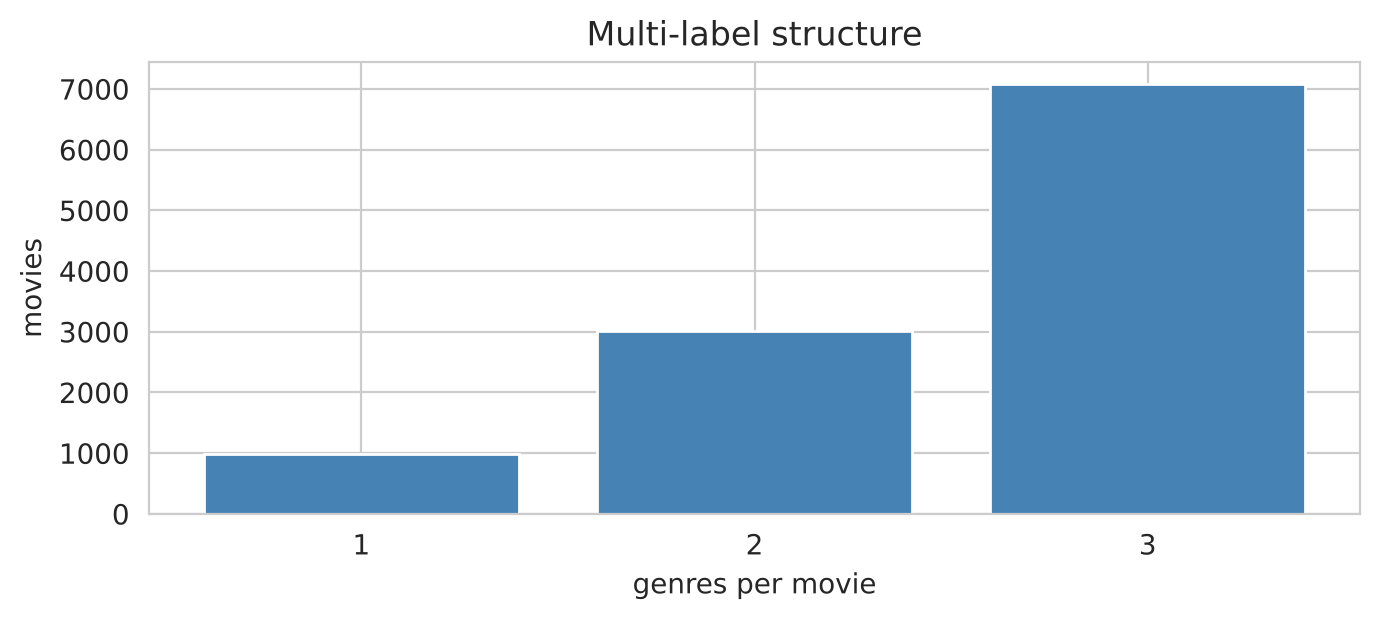

Mean 2.55 genres per movie, median 3, max 3


In [10]:
n_genres = movies[GENRES].sum(axis=1)
counts = n_genres.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(counts.index, counts.values, color='steelblue')
ax.set_xlabel('genres per movie')
ax.set_ylabel('movies')
ax.set_xticks(counts.index)
ax.set_title('Multi-label structure')
plt.tight_layout()
plt.show()
print(f'Mean {n_genres.mean():.2f} genres per movie, median {n_genres.median():.0f}, max {n_genres.max()}')

**Interpretation:** No movie has more than three genres, and 64% (7,090 of 11,089) have exactly three. The labels are multi-label, so each genre must be its own yes/no problem, which is how Notebook 2 is set up. The cap of three also means a movie can lack a genre it plausibly has because its three slots were used, so some "negative" labels are really "unlisted". That sets a ceiling on how well any text model can score.

### 3.2 Correlation of the genre columns

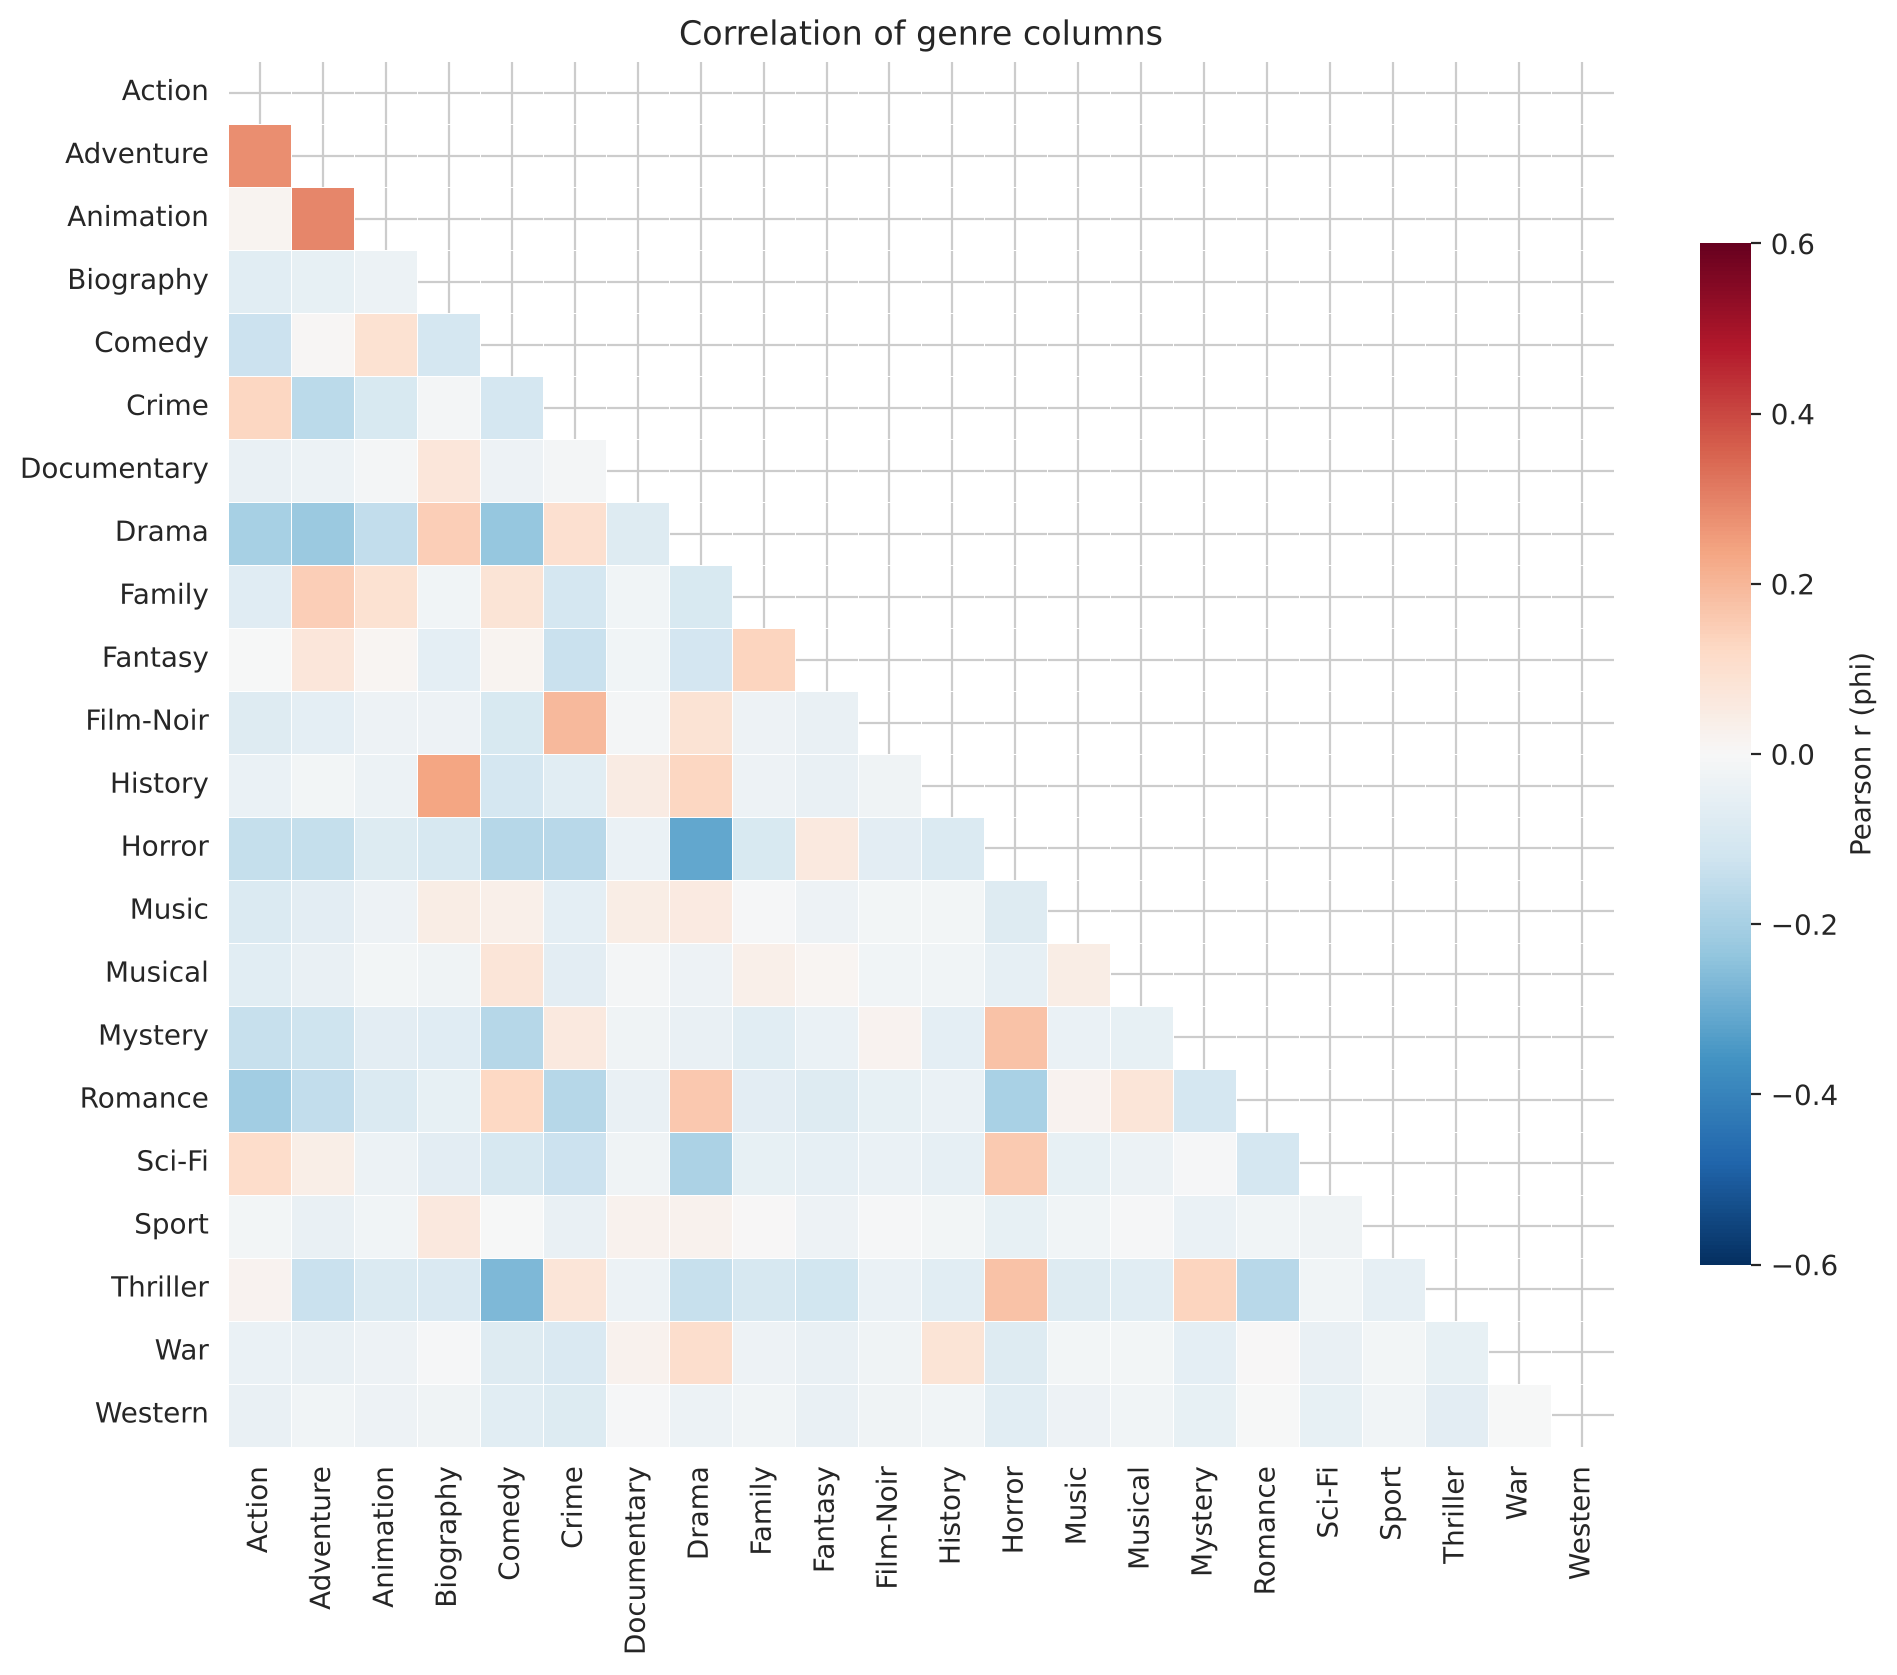

,genre_a,genre_b,r
0,Horror,Drama,-0.31
1,Thriller,Comedy,-0.27
2,Drama,Comedy,-0.23
3,Drama,Adventure,-0.22
4,Romance,Action,-0.21
5,Animation,Adventure,0.29
6,Adventure,Action,0.28
7,History,Biography,0.24
8,Film-Noir,Crime,0.20
9,Mystery,Horror,0.18


In [11]:
live = [g for g in GENRES if movies[g].sum() >= 10]          # Adult and News have one positive each, so no correlation to read
corr = movies[live].corr()
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap='RdBu_r', center=0, vmin=-0.6, vmax=0.6,
            square=True, linewidths=0.3, cbar_kws={'shrink': 0.7, 'label': 'Pearson r (phi)'}, ax=ax)
ax.set_title('Correlation of genre columns')
plt.tight_layout()
plt.show()

pairs = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1)).stack().dropna().sort_values()
extremes = pd.concat([pairs.head(5), pairs.tail(5)[::-1]])
pd.DataFrame({'genre_a': [a for a, b in extremes.index], 'genre_b': [b for a, b in extremes.index],
              'r': extremes.round(2).values})

**Interpretation:** Correlations are weak. The strongest positive pairs are Animation and Adventure (0.29), Adventure and Action (0.28), History and Biography (0.24), Film-Noir and Crime (0.20) and Mystery and Horror (0.18). The strongest negative pairs are Horror and Drama (-0.31), Thriller and Comedy (-0.27), Drama and Comedy (-0.23), Drama and Adventure (-0.22) and Romance and Action (-0.21). No pair exceeds 0.31 in absolute value, so no genre is a duplicate of another and separate classifiers are justified. The negative pairs are plausible tone clashes, and the three-genre cap likely adds to them, because Drama alone takes a slot in more than half of all movies. Adult and News are left out of the heatmap because one positive each gives nothing to correlate.

## 4. Text characteristics and vocabulary

### 4.1 Synopsis length

Tokens are approximated as characters divided by 4, a common rule of thumb for English text. The estimate matters later for choosing how much synopsis text to send to the LLM teacher in Notebook 2.

                 mean  median    min      max
characters     5501.0  4001.0  560.0  63959.0
words           961.0   688.0  101.0  11406.0
approx_tokens  1375.0  1000.0  140.0  15990.0


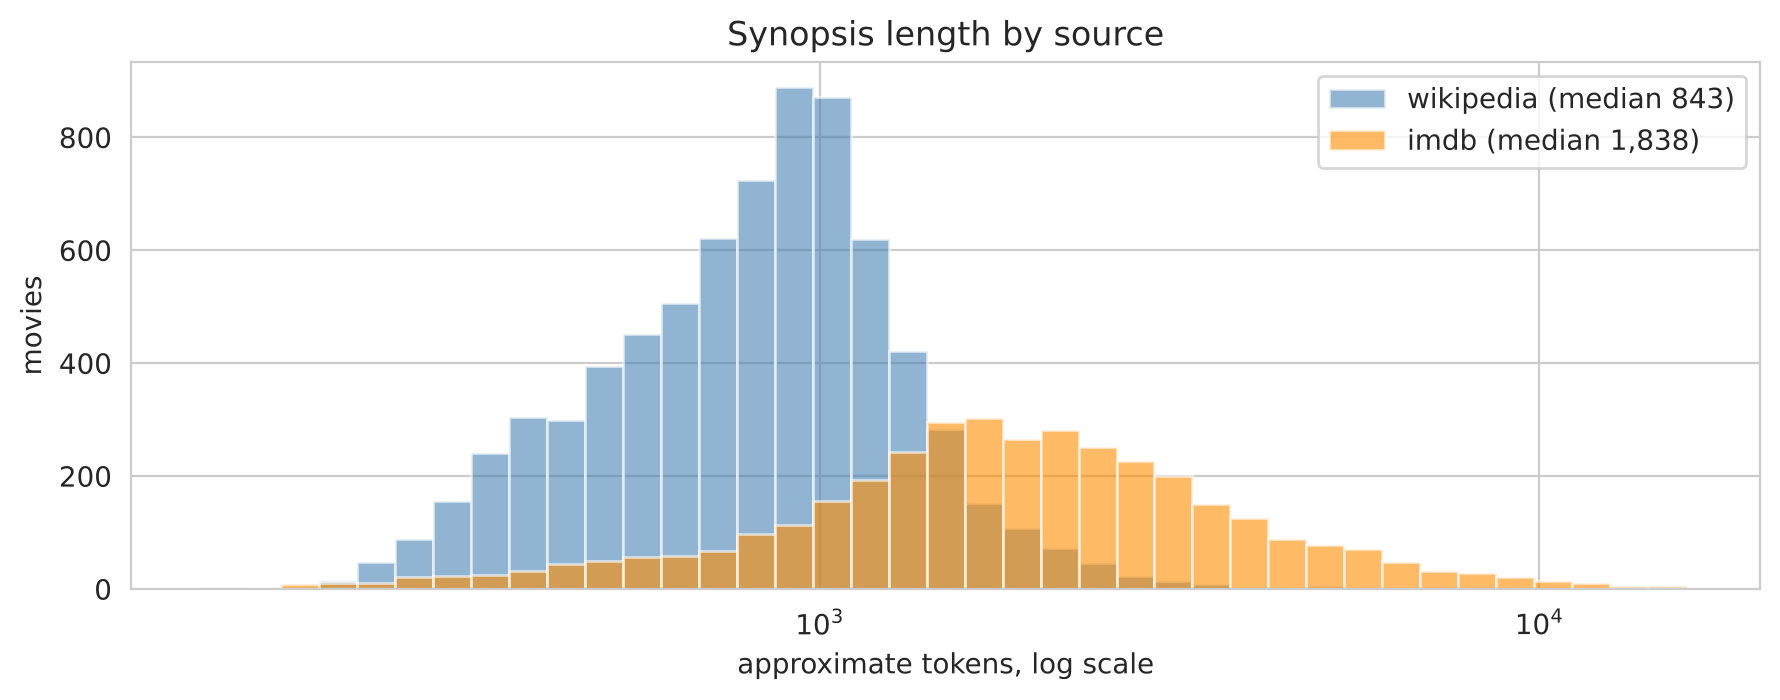

Synopses above 2,000 / 4,000 / 8,000 approx tokens: [1858, 449, 78]


In [12]:
lengths = pd.DataFrame({'characters': movies['plot_synopsis'].str.len(),
                        'words': movies['plot_synopsis'].str.split().str.len()})
lengths['approx_tokens'] = lengths['characters'] / 4
print(lengths.agg(['mean', 'median', 'min', 'max']).round(0).T.to_string())

fig, ax = plt.subplots(figsize=(9, 3.6))
for src, color in (('wikipedia', 'steelblue'), ('imdb', 'darkorange')):
    vals = lengths.loc[movies['synopsis_source'] == src, 'approx_tokens']
    ax.hist(vals, bins=np.logspace(np.log10(lengths['approx_tokens'].min()), np.log10(lengths['approx_tokens'].max()), 40),
            alpha=0.6, color=color, label=f'{src} (median {vals.median():,.0f})')
ax.set_xscale('log')
ax.set_xlabel('approximate tokens, log scale')
ax.set_ylabel('movies')
ax.set_title('Synopsis length by source')
ax.legend()
plt.tight_layout()
plt.show()
print('Synopses above 2,000 / 4,000 / 8,000 approx tokens:',
      [int((lengths['approx_tokens'] > t).sum()) for t in (2000, 4000, 8000)])

**Interpretation:** Synopses are long and right-skewed. The median is 4,001 characters (688 words, about 1,000 tokens) and the mean 5,501 characters (about 1,375 tokens), with a range of 560 to 63,959 characters (140 to 15,990 tokens). Length depends strongly on source: IMDB synopses have a median of about 1,838 tokens against 843 for Wikipedia, more than twice as long. Only 449 synopses (4%) exceed 4,000 tokens and 78 exceed 8,000, so a truncation cap of about 4,000 tokens would touch few of them when the LLM teacher in Notebook 2 reads its sample.

### 4.2 Vocabulary: which words separate the genres?

For each word, count the movies whose synopsis contains it (document frequency). Stop words and words under three letters are ignored. For a genre, a word's **lift** is the share of that genre's movies containing it divided by the share of all movies containing it. A lift of 3 means the word is three times as common inside the genre as overall. Words must appear in at least 30 movies of the genre, so single-franchise character names do not dominate. These are plain counts, not a vectorizer.

In [13]:
STOP = set(ENGLISH_STOP_WORDS)
doc_terms = [{w for w in re.findall(r'[a-z]{3,}', text.lower()) if w not in STOP} for text in movies['plot_synopsis']]
N = len(doc_terms)
doc_freq = Counter(w for terms in doc_terms for w in terms)

common = pd.DataFrame(doc_freq.most_common(12), columns=['term', 'movies'])
common['pct_of_movies'] = (100 * common['movies'] / N).round(1)
print('Most common terms overall:')
common.T

Most common terms overall:


,0,1,2,3,4,5,6,7,8,9,10,11
term,tells,time,later,finds,takes,goes,away,man,home,new,night,day
movies,6397,6340,6134,5827,5765,5599,5550,5549,5523,5386,5122,5084
pct_of_movies,57.7,57.2,55.3,52.5,52.0,50.5,50.0,50.0,49.8,48.6,46.2,45.8


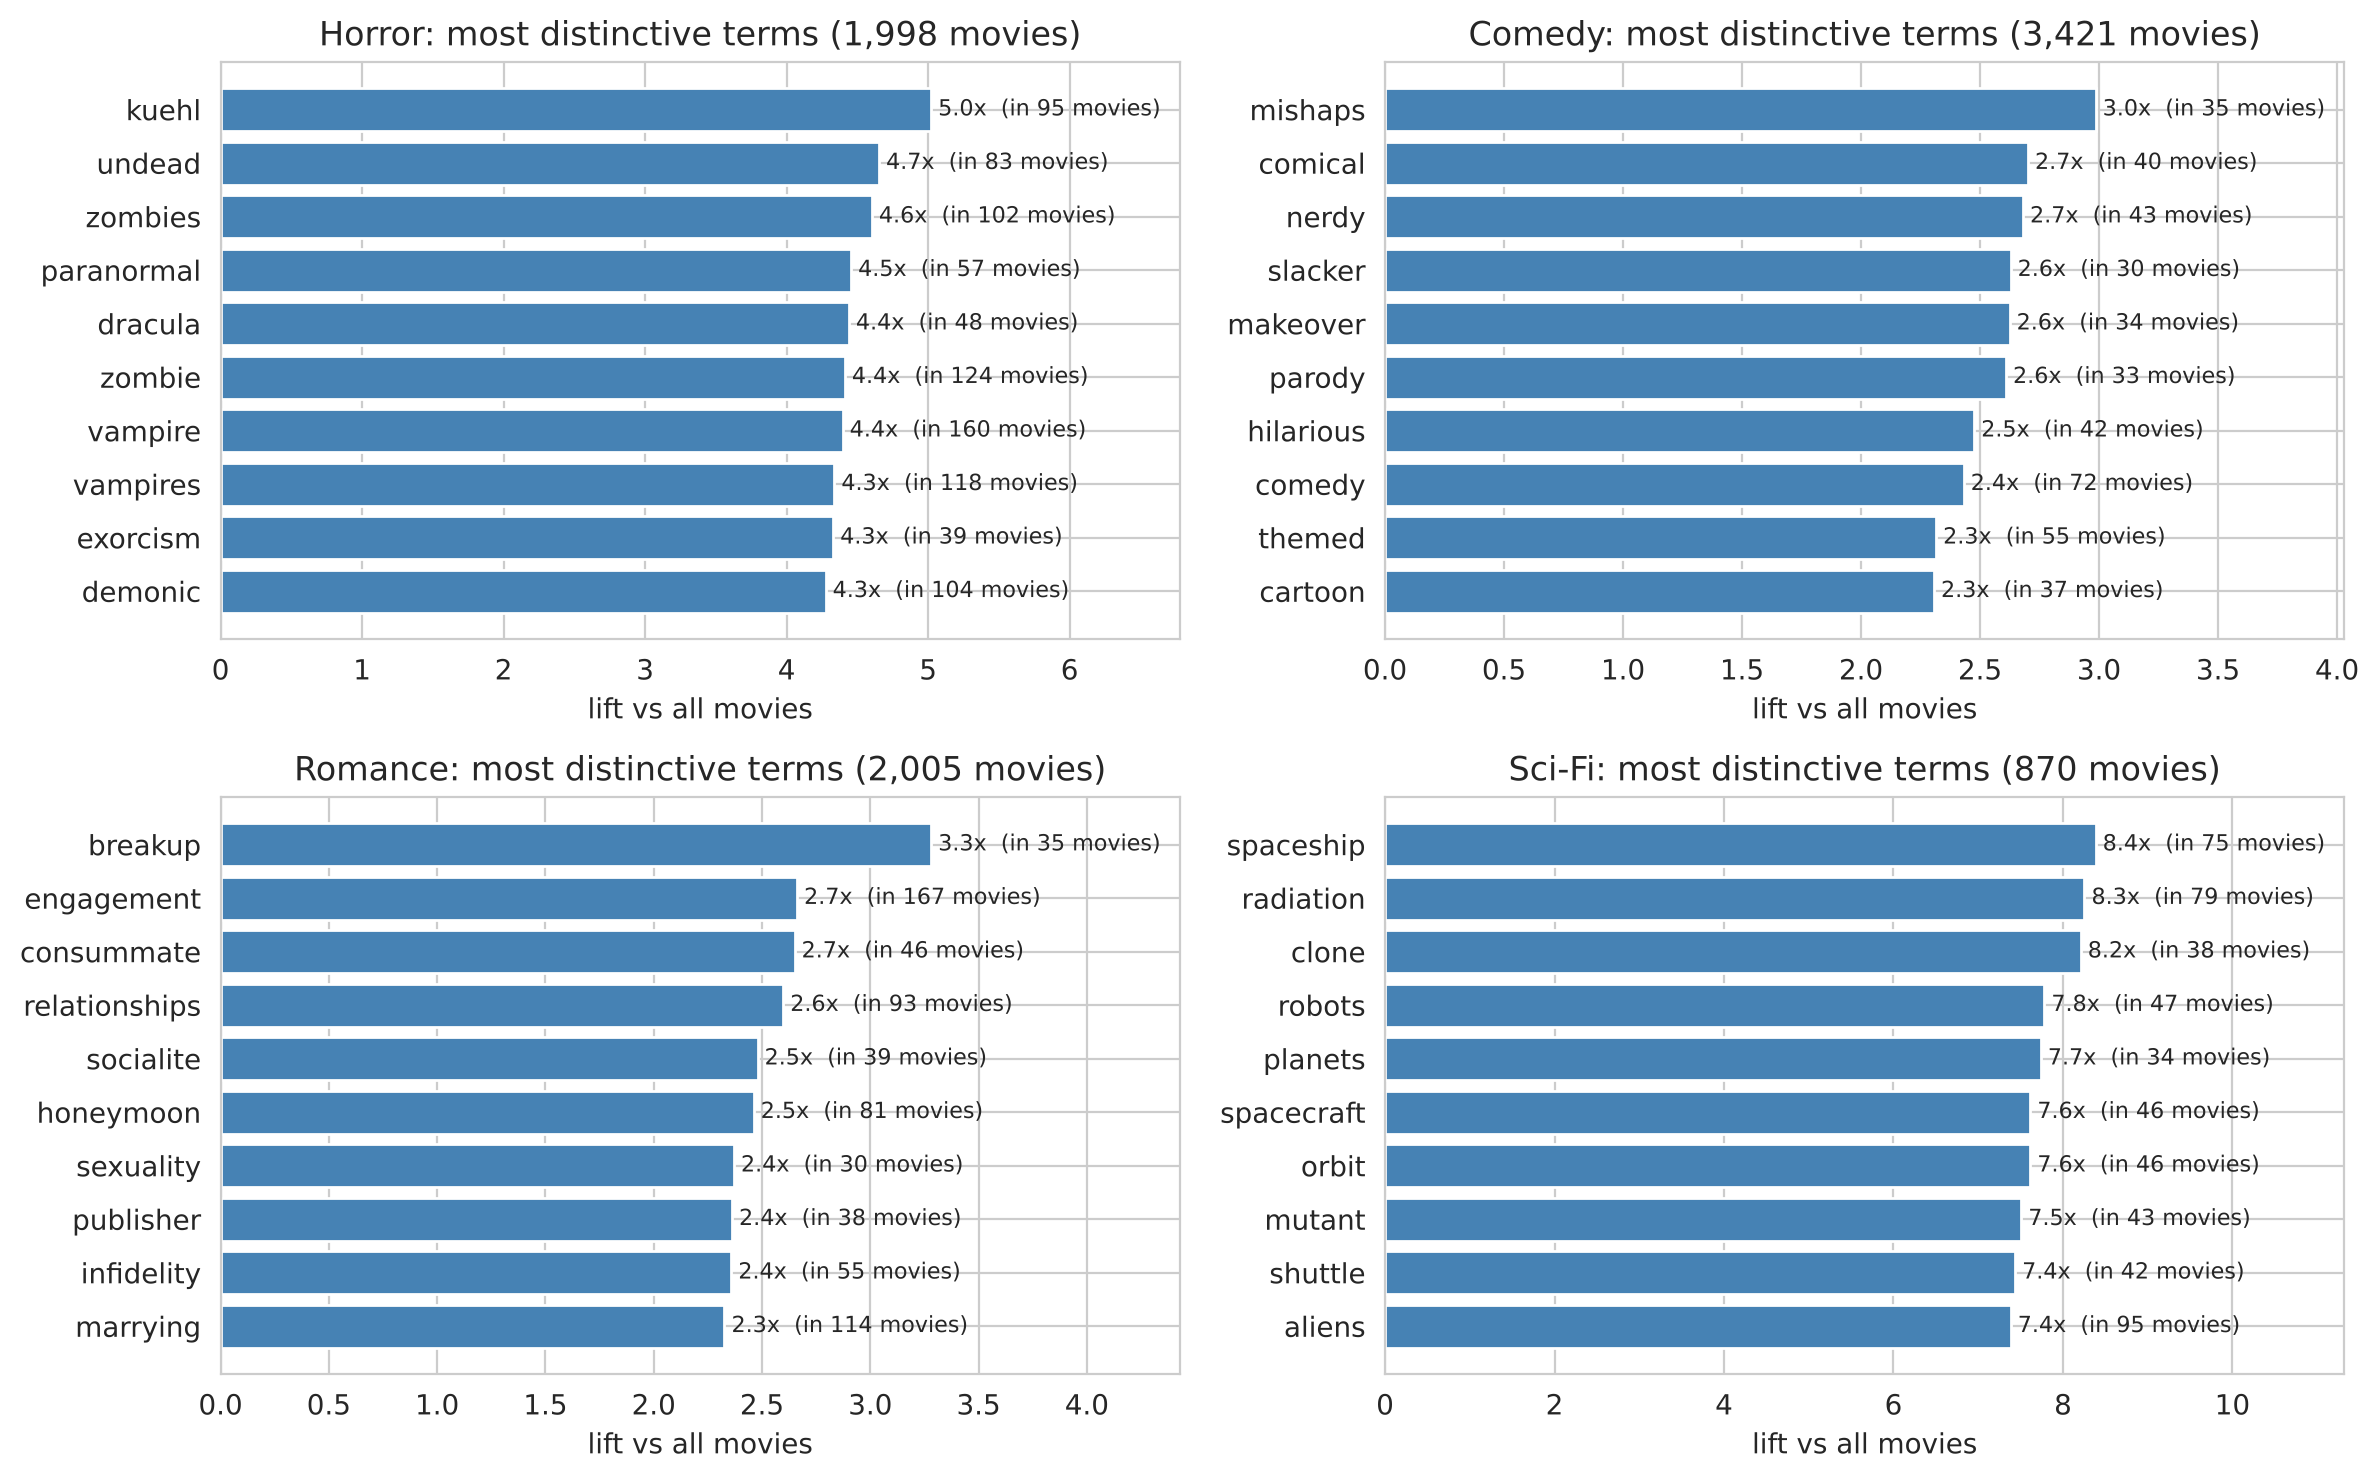

In [14]:
def distinctive(genre, top=10, min_docs=30):
    idx = np.flatnonzero(movies[genre].to_numpy() == 1)
    genre_freq = Counter(w for i in idx for w in doc_terms[i])
    rows = [(w, c, (c / len(idx)) / (doc_freq[w] / N)) for w, c in genre_freq.items() if c >= min_docs]
    return pd.DataFrame(rows, columns=['term', 'genre_movies', 'lift']).nlargest(top, 'lift')

SHOWN = ['Horror', 'Comedy', 'Romance', 'Sci-Fi']
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, genre in zip(axes.ravel(), SHOWN):
    top = distinctive(genre)
    ax.barh(top['term'], top['lift'], color='steelblue')
    for y, (v, c) in enumerate(zip(top['lift'], top['genre_movies'])):
        ax.text(v, y, f' {v:.1f}x  (in {c} movies)', va='center', fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, top['lift'].max() * 1.35)
    ax.set_title(f"{genre}: most distinctive terms ({int(movies[genre].sum()):,} movies)")
    ax.set_xlabel('lift vs all movies')
plt.tight_layout()
plt.show()

**Interpretation:** The most common terms (`tells`, `time`, `later`, `finds`, `takes`, `goes`) each appear in roughly half of all synopses regardless of genre, so they cannot separate classes. Genre-specific vocabulary exists and is strongest where the genre has concrete plot content. Sci-Fi words are 7 to 8 times as common inside the genre (`spaceship` 8.4x, `radiation`, `clone`, `robots`, `planets`, `aliens`), and Horror words 4 to 5 times (`undead`, `zombies`, `paranormal`, `vampire`, `exorcism`, `demonic`). Comedy and Romance are weaker, topping out near 3x with softer words (`mishaps`, `parody`, `hilarious` and `breakup`, `engagement`, `honeymoon`, `infidelity`). The prediction for Notebook 2 is that Sci-Fi and Horror will be easier for TF-IDF than Comedy and Romance. One term is not a plot word: the top Horror term `kuehl` is a submitter credit, checked next.

### 4.3 Synopsis source and attribution artifacts

The top Horror term in 4.2 is not a plot word. `kuehl` comes from submitter credits written into IMDB synopses (for example "Original Synopsis by bj_kuehl"). The first table asks whether the synopsis source (Wikipedia or IMDB) is related to genre. The second checks how credited synopses are labeled.

In [15]:
by_source = movies.groupby('synopsis_source')[GENRES].mean().T * 100
by_source['imdb_minus_wikipedia_pts'] = by_source['imdb'] - by_source['wikipedia']
common_genres = balance.index[balance['rate_pct'] >= 5]
print('Genre rate (%) by synopsis source, genres with at least 5% positives:')
by_source.loc[common_genres].sort_values('imdb_minus_wikipedia_pts').round(1)

Genre rate (%) by synopsis source, genres with at least 5% positives:


synopsis_source,imdb,wikipedia,imdb_minus_wikipedia_pts
Drama,47.0,55.8,-8.9
Comedy,25.7,33.4,-7.7
Romance,13.0,20.6,-7.7
Crime,20.4,22.0,-1.6
Fantasy,8.6,7.5,1.2
Mystery,13.8,9.6,4.1
Action,25.7,21.2,4.5
Adventure,19.0,13.7,5.3
Sci-Fi,12.0,5.8,6.2
Thriller,22.2,15.4,6.8


In [16]:
credited = movies['plot_synopsis'].str.contains(r'bj[_ ]?kuehl', case=False)
print(f"{credited.sum()} synopses carry the 'bj_kuehl' credit; sources: {movies.loc[credited, 'synopsis_source'].value_counts().to_dict()}")
pd.DataFrame({'credited_%': movies.loc[credited, GENRES].mean() * 100, 'all_movies_%': movies[GENRES].mean() * 100}
             ).round(1).loc[['Horror', 'Thriller', 'Drama', 'Comedy', 'Romance']]

105 synopses carry the 'bj_kuehl' credit; sources: {'imdb': 105}


,credited_%,all_movies_%
Horror,90.5,18.0
Thriller,13.3,17.6
Drama,24.8,52.8
Comedy,11.4,30.9
Romance,3.8,18.1


**Interpretation:** Two artifacts could let a model score well without reading the plot. First, source is related to genre: IMDB-sourced synopses are 24.3% Horror against 14.9% for Wikipedia (+9.4 points), with Thriller +6.8, Sci-Fi +6.2 and Adventure +5.3, while Drama (-8.9), Comedy (-7.7) and Romance (-7.7) are less common. IMDB synopses are also more than twice as long, so style and length differ by source. Second, 105 synopses (all from IMDB) carry the credit "bj_kuehl", and 90.5% of them are labeled Horror against 18.0% overall. A model would learn that credit as a Horror signal. Other submitter credits appear too. Recommendation for Notebook 2: remove "Original Synopsis by ..." style credit lines from the text before vectorizing and state that in a markdown cell. Notebook 3 can then check that no credit name appears among the top coefficients or SHAP words.

## 5. Summary and decisions for Notebooks 2 and 3

**What the EDA found and what it means for the next notebooks**

- **Data:** 11,824 movies, 24 genre columns, no duplicates and no empty synopses. The provided train/val/test splits have matching genre rates (gaps of at most 2.0 points) and matching source mix.
- **Vote filter:** `MIN_VOTES = 500` drops 735 movies (6.2%, evenly across splits) and leaves 7,122 train, 1,758 val and 2,209 test movies. Notebooks 2 and 3 apply it.
- **Class balance:** only 11 of 24 genres reach 5% positives (Drama, Comedy, Action, Crime, Romance, Horror, Thriller, Adventure, Mystery, Fantasy, Sci-Fi), and Drama is on 52.8% of movies. Accuracy would mislead, so Notebook 2 should rely on macro-F1 and class weights.
- **Labels:** every movie has one to three genres (64% have three), so each genre is a separate yes/no problem. The cap leaves some "negatives" that are really unlisted genres.
- **Text:** the median synopsis is about 1,000 tokens (mean 1,375), with a 4% tail above 4,000 tokens that matters only for the LLM teacher's context.
- **Vocabulary:** Sci-Fi and Horror have strong, concrete signature words; Comedy and Romance are softer, so expect lower scores for them.
- **Artifacts:** synopsis source predicts genre (IMDB-sourced synopses are 9.4 points more often Horror) and the `bj_kuehl` credit is a near-perfect Horror marker. Strip credit lines before vectorizing in Notebook 2 and check the top words in Notebook 3.